# Boston Housing: Statistics for Data Science with Python, final project

**Scenario.** A housing agency in Boston wants to know: (1) whether houses bounding the Charles River have a different median value, (2) whether median value differs across the share of owner-occupied units built before 1940, (3) whether nitric oxide concentration is related to the share of non-retail business acres, and (4) how an extra unit of weighted distance to the five Boston employment centres changes median value.

**Data.** `boston_housing.csv` from the course's public storage (506 tracts). Variables used: MEDV (median home value, $1000s), CHAS (1 if tract bounds the river), AGE (share of units built before 1940), NOX (nitric oxide, parts per 10 million), INDUS (share of non-retail business acres), DIS (weighted distance to five employment centres), PTRATIO (pupil-teacher ratio).

All tests use alpha = 0.05.

## Task 1: Familiarize yourself with the dataset

In [1]:
import pandas as pd, numpy as np
import matplotlib.pyplot as plt, seaborn as sns
import scipy.stats as stats
import statsmodels.api as sm
sns.set_theme(style="whitegrid")

url = "https://cf-courses-data.s3.us.cloud-object-storage.appdomain.cloud/IBMDeveloperSkillsNetwork-ST0151EN-SkillsNetwork/labs/boston_housing.csv"
try:
    df = pd.read_csv(url, index_col=0)
except Exception:
    df = pd.read_csv("data/boston_housing.csv", index_col=0)  # local copy of the same file
print(df.shape)
df.head()

(506, 13)


,CRIM,ZN,INDUS,CHAS,NOX,RM,AGE,DIS,RAD,TAX,PTRATIO,LSTAT,MEDV
0,0.00632,18.0,2.31,0.0,0.538,6.575,65.2,4.0900,1.0,296.0,15.3,4.98,24.0
1,0.02731,0.0,7.07,0.0,0.469,6.421,78.9,4.9671,2.0,242.0,17.8,9.14,21.6
2,0.02729,0.0,7.07,0.0,0.469,7.185,61.1,4.9671,2.0,242.0,17.8,4.03,34.7
3,0.03237,0.0,2.18,0.0,0.458,6.998,45.8,6.0622,3.0,222.0,18.7,2.94,33.4
4,0.06905,0.0,2.18,0.0,0.458,7.147,54.2,6.0622,3.0,222.0,18.7,5.33,36.2


### Data types of each column

In [2]:
df.dtypes

CRIM       float64
ZN         float64
INDUS      float64
CHAS       float64
NOX        float64
RM         float64
AGE        float64
DIS        float64
RAD        float64
TAX        float64
PTRATIO    float64
LSTAT      float64
MEDV       float64
dtype: object

### Missing values in each column

In [3]:
df.isna().sum()

CRIM       0
ZN         0
INDUS      0
CHAS       0
NOX        0
RM         0
AGE        0
DIS        0
RAD        0
TAX        0
PTRATIO    0
LSTAT      0
MEDV       0
dtype: int64

### Duplicate rows

In [4]:
print(df.duplicated().sum(), 'duplicate rows')

0 duplicate rows


**Finding.** All 13 columns are numeric, with no missing values and no duplicate rows, so no cleaning is needed before the analysis.

### Correlation matrix

In [5]:
df.corr().round(2)

,CRIM,ZN,INDUS,CHAS,NOX,RM,AGE,DIS,RAD,TAX,PTRATIO,LSTAT,MEDV
CRIM,1.00,-0.20,0.41,-0.06,0.42,-0.22,0.35,-0.38,0.63,0.58,0.29,0.46,-0.39
ZN,-0.20,1.00,-0.53,-0.04,-0.52,0.31,-0.57,0.66,-0.31,-0.31,-0.39,-0.41,0.36
INDUS,0.41,-0.53,1.00,0.06,0.76,-0.39,0.64,-0.71,0.60,0.72,0.38,0.60,-0.48
CHAS,-0.06,-0.04,0.06,1.00,0.09,0.09,0.09,-0.10,-0.01,-0.04,-0.12,-0.05,0.18
NOX,0.42,-0.52,0.76,0.09,1.00,-0.30,0.73,-0.77,0.61,0.67,0.19,0.59,-0.43
RM,-0.22,0.31,-0.39,0.09,-0.30,1.00,-0.24,0.21,-0.21,-0.29,-0.36,-0.61,0.70
AGE,0.35,-0.57,0.64,0.09,0.73,-0.24,1.00,-0.75,0.46,0.51,0.26,0.60,-0.38
DIS,-0.38,0.66,-0.71,-0.10,-0.77,0.21,-0.75,1.00,-0.49,-0.53,-0.23,-0.50,0.25
RAD,0.63,-0.31,0.60,-0.01,0.61,-0.21,0.46,-0.49,1.00,0.91,0.46,0.49,-0.38
TAX,0.58,-0.31,0.72,-0.04,0.67,-0.29,0.51,-0.53,0.91,1.00,0.46,0.54,-0.47


**Finding.** MEDV is most strongly related to LSTAT (-0.74) and RM (0.70). Among the variables management asked about, NOX and INDUS are strongly related (0.76), while MEDV has weaker correlations with AGE (-0.38), DIS (0.25) and CHAS (0.18). Correlation alone does not show cause.

## Task 2: Generate descriptive statistics and visualizations

### Descriptive statistics

In [6]:
df.describe().round(2)

,CRIM,ZN,INDUS,CHAS,NOX,RM,AGE,DIS,RAD,TAX,PTRATIO,LSTAT,MEDV
count,506.00,506.00,506.00,506.00,506.00,506.00,506.00,506.00,506.00,506.00,506.00,506.00,506.00
mean,3.61,11.36,11.14,0.07,0.55,6.28,68.57,3.80,9.55,408.24,18.46,12.65,22.53
std,8.60,23.32,6.86,0.25,0.12,0.70,28.15,2.11,8.71,168.54,2.16,7.14,9.20
min,0.01,0.00,0.46,0.00,0.38,3.56,2.90,1.13,1.00,187.00,12.60,1.73,5.00
25%,0.08,0.00,5.19,0.00,0.45,5.89,45.02,2.10,4.00,279.00,17.40,6.95,17.02
50%,0.26,0.00,9.69,0.00,0.54,6.21,77.50,3.21,5.00,330.00,19.05,11.36,21.20
75%,3.68,12.50,18.10,0.00,0.62,6.62,94.07,5.19,24.00,666.00,20.20,16.96,25.00
max,88.98,100.00,27.74,1.00,0.87,8.78,100.00,12.13,24.00,711.00,22.00,37.97,50.00


**Finding.** The average tract has a median home value of about $22,500 (MEDV, median of tracts 21.2, capped at 50). AGE has a mean of 68.6 and a median of 77.5, so most tracts contain a lot of pre-1940 housing. CRIM is very skewed: mean 3.61 against a median of 0.26.

### Plot 1. Boxplot of MEDV (median value of owner-occupied homes)

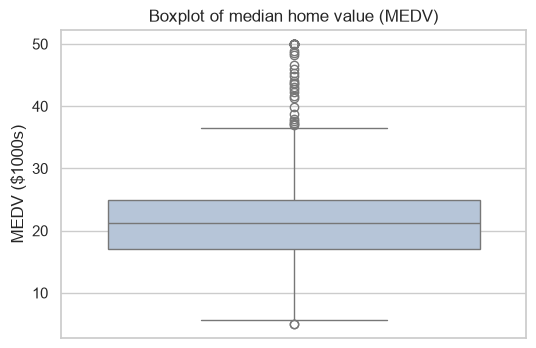

count    506.000000
mean      22.532806
std        9.197104
min        5.000000
25%       17.025000
50%       21.200000
75%       25.000000
max       50.000000
Name: MEDV, dtype: float64


In [7]:
plt.figure(figsize=(6,4))
sns.boxplot(y=df["MEDV"], color="lightsteelblue")
plt.title("Boxplot of median home value (MEDV)")
plt.ylabel("MEDV ($1000s)")
plt.show()
print(df["MEDV"].describe())

**Finding.** The median of MEDV is about 21.2 (i.e. $21,200) and the middle half of tracts lies between about 17 and 25. The upper whisker ends near 37, and a cluster of tracts above that is flagged as outliers, with a pile-up at exactly 50, which looks like a cap in the data. The distribution is right-skewed.

### Plot 2. Bar plot of CHAS (Charles River dummy)

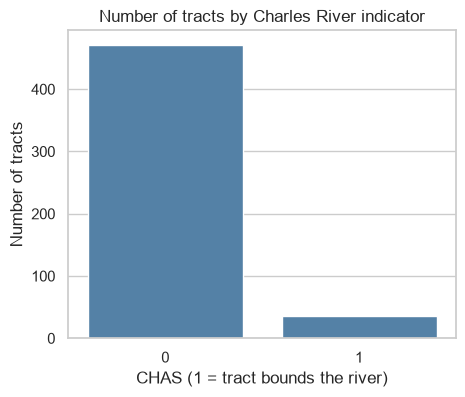

CHAS
0.0    471
1.0     35
Name: count, dtype: int64


In [8]:
counts = df["CHAS"].value_counts().sort_index()
plt.figure(figsize=(5,4))
sns.barplot(x=counts.index.astype(int), y=counts.values, color="steelblue")
plt.title("Number of tracts by Charles River indicator")
plt.xlabel("CHAS (1 = tract bounds the river)")
plt.ylabel("Number of tracts")
plt.show()
print(counts)

**Finding.** Only a small minority of tracts (35 of 506, about 7%) bound the river. The groups are very unbalanced, which matters for the t-test below.

### Plot 3. Boxplot of MEDV by AGE group (35 years and younger, 35 to 70, 70 and older)

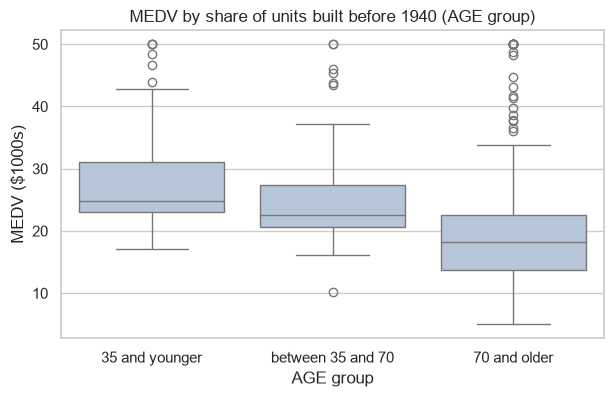

                   count   mean  median   std
age_group                                    
35 and younger        91  27.78    24.8  7.64
between 35 and 70    128  24.95    22.6  6.97
70 and older         287  19.79    18.2  9.52


In [9]:
df["age_group"] = pd.cut(df["AGE"], bins=[0, 35, 70, 100],
                         labels=["35 and younger", "between 35 and 70", "70 and older"])
plt.figure(figsize=(7,4))
sns.boxplot(x="age_group", y="MEDV", data=df, color="lightsteelblue")
plt.title("MEDV by share of units built before 1940 (AGE group)")
plt.xlabel("AGE group")
plt.ylabel("MEDV ($1000s)")
plt.show()
print(df.groupby("age_group", observed=True)["MEDV"].agg(["count","mean","median","std"]).round(2))

**Finding.** Median value falls as the share of old housing rises: tracts in the youngest group have the highest values, tracts with 70 or more percent old units the lowest. (Note: AGE is a percentage, so the groups are bands of that percentage, as the task describes.)

### Plot 4. Scatter plot of NOX vs INDUS

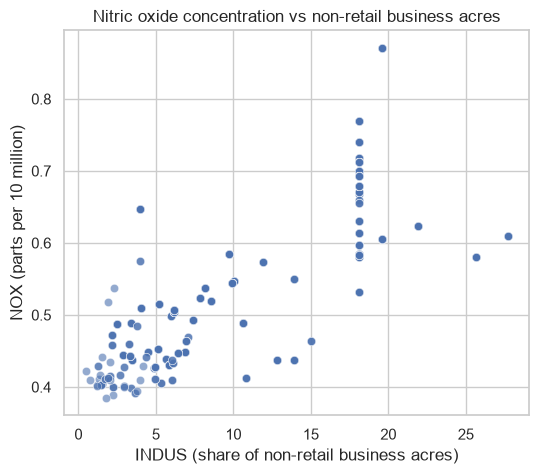

In [10]:
plt.figure(figsize=(6,5))
sns.scatterplot(x="INDUS", y="NOX", data=df, alpha=0.6)
plt.title("Nitric oxide concentration vs non-retail business acres")
plt.xlabel("INDUS (share of non-retail business acres)")
plt.ylabel("NOX (parts per 10 million)")
plt.show()

**Finding.** The cloud slopes upward: towns with more non-retail (industrial) land tend to have higher nitric oxide. The relationship looks roughly linear, with a vertical stripe of tracts at INDUS = 18.1 that share a wide range of NOX values.

### Plot 5. Histogram of PTRATIO (pupil-teacher ratio)

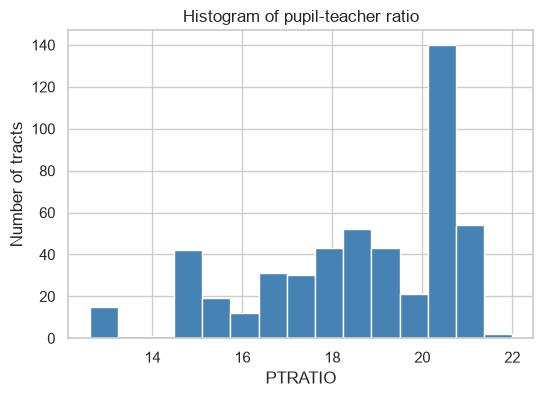

count    506.000000
mean      18.455534
std        2.164946
min       12.600000
25%       17.400000
50%       19.050000
75%       20.200000
max       22.000000
Name: PTRATIO, dtype: float64


In [11]:
plt.figure(figsize=(6,4))
plt.hist(df["PTRATIO"], bins=15, color="steelblue", edgecolor="white")
plt.title("Histogram of pupil-teacher ratio")
plt.xlabel("PTRATIO")
plt.ylabel("Number of tracts")
plt.show()
print(df["PTRATIO"].describe())

**Finding.** PTRATIO ranges from about 12.6 to 22 and is left-skewed, with the largest bar near 20 to 21. Many tracts share the same ratio, which is why one tall bar stands out.

## Task 3: Apply statistical tests (alpha = 0.05)

### Test 1. Do houses bounding the Charles River differ in median value? (t-test, independent samples)

- H0: mean MEDV is the same for CHAS = 1 and CHAS = 0.
- H1: the means are different.
- Alpha = 0.05.

Levene's test is used first to choose between the equal-variance and Welch version.

In [12]:
a = df.loc[df.CHAS == 1, "MEDV"]
b = df.loc[df.CHAS == 0, "MEDV"]
print("Levene:", stats.levene(a, b))
print("Student:", stats.ttest_ind(a, b, equal_var=True))
print("Welch  :", stats.ttest_ind(a, b, equal_var=False))
print("means:", round(a.mean(),2), round(b.mean(),2))

Levene: LeveneResult(statistic=np.float64(4.590342218715871), pvalue=np.float64(0.032630976006326064))
Student: TtestResult(statistic=np.float64(3.996437466090509), pvalue=np.float64(7.390623170519907e-05), df=np.float64(504.0))
Welch  : TtestResult(statistic=np.float64(3.113291312794837), pvalue=np.float64(0.003567170098137519), df=np.float64(36.876408797611994))
means: 28.44 22.09


**Conclusion.** Levene's test is significant, so the variances are not equal and the Welch version is the appropriate one. Both versions give p < 0.05 (Welch p is about 0.004), so we reject H0: tracts bounding the river have a higher mean MEDV (about 28.4 vs 22.1, i.e. roughly $6,300 more). This is a difference in averages, not proof that the river causes it.

### Test 2. Does MEDV differ across AGE groups? (one-way ANOVA)

- H0: mean MEDV is equal in the three AGE groups.
- H1: at least one group mean is different.
- Alpha = 0.05.

In [13]:
g = [d["MEDV"].values for _, d in df.groupby("age_group", observed=True)]
print("Levene:", stats.levene(*g))
print(stats.f_oneway(*g))
from statsmodels.stats.multicomp import pairwise_tukeyhsd
print(pairwise_tukeyhsd(df["MEDV"], df["age_group"].astype(str)))

Levene: LeveneResult(statistic=np.float64(3.471820890881101), pvalue=np.float64(0.031806778061336305))
F_onewayResult(statistic=np.float64(36.40764999196599), pvalue=np.float64(1.7105011022701404e-15))


          Multiple Comparison of Means - Tukey HSD, FWER=0.05           
    group1           group2      meandiff p-adj   lower    upper  reject
------------------------------------------------------------------------
35 and younger      70 and older  -7.9824    0.0 -10.4182 -5.5467   True
35 and younger between 35 and 70  -2.8282 0.0447  -5.6043  -0.052   True
  70 and older between 35 and 70   5.1543    0.0   3.0024  7.3062   True
------------------------------------------------------------------------


**Conclusion.** The F-test p-value is far below 0.05, so we reject H0: median value differs across the age groups. Tukey HSD finds all three pairs different: 70 and older is about 8.0 below 35 and younger and about 5.2 below the middle group, and the middle group is about 2.8 below 35 and younger (that last pair is borderline, adjusted p = 0.045). The Levene test also flags unequal variances, so the F-test is approximate, but the gap between groups is large enough that the conclusion is not in doubt.

### Test 3. Is NOX related to INDUS? (Pearson correlation)

- H0: there is no linear relationship between NOX and INDUS (rho = 0).
- H1: there is a linear relationship (rho != 0).
- Alpha = 0.05.

In [14]:
r, p = stats.pearsonr(df["NOX"], df["INDUS"])
print("r =", round(r,4), " r^2 =", round(r**2,4), " p =", p)

r = 0.7637  r^2 = 0.5832  p = 7.913361061242816e-98


**Conclusion.** r is about 0.76 and p is essentially zero, so we reject H0. We cannot conclude that there is no relationship: NOX and INDUS have a strong positive linear association, and INDUS explains about 58% of the variation in NOX (r squared).

### Test 4. Impact of weighted distance to employment centres (DIS) on MEDV (simple linear regression)

- H0: the slope of MEDV on DIS is 0.
- H1: the slope is not 0.
- Alpha = 0.05.

In [15]:
X = sm.add_constant(df["DIS"])
model = sm.OLS(df["MEDV"], X).fit()
print(model.summary())

                            OLS Regression Results                            
Dep. Variable:                   MEDV   R-squared:                       0.062
Model:                            OLS   Adj. R-squared:                  0.061
Method:                 Least Squares   F-statistic:                     33.58
Date:                Wed, 04 Nov 2026   Prob (F-statistic):           1.21e-08
Time:                        19:57:21   Log-Likelihood:                -1823.9
No. Observations:                 506   AIC:                             3652.
Df Residuals:                     504   BIC:                             3660.
Df Model:                           1                                         
Covariance Type:            nonrobust                                         
                 coef    std err          t      P>|t|      [0.025      0.975]
------------------------------------------------------------------------------
const         18.3901      0.817     22.499      0.0

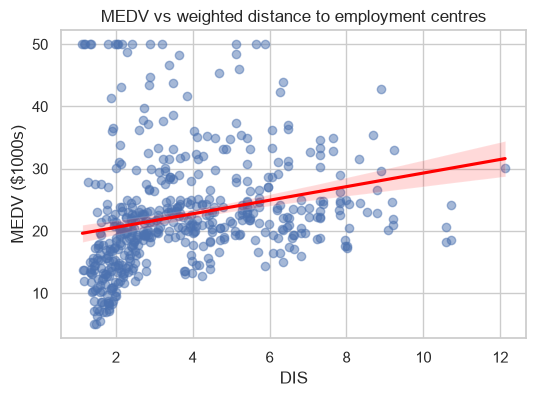

In [16]:
plt.figure(figsize=(6,4))
sns.regplot(x="DIS", y="MEDV", data=df, scatter_kws={"alpha":0.5}, line_kws={"color":"red"})
plt.title("MEDV vs weighted distance to employment centres")
plt.xlabel("DIS")
plt.ylabel("MEDV ($1000s)")
plt.show()

**Conclusion.** The slope is about 1.09 with p far below 0.05, so we reject H0. Each additional unit of weighted distance is associated with about $1,090 higher median value on average. R squared is only about 0.06, so DIS alone explains a small share of the variation, and the straight line is a crude description of a curved cloud.

## Summary

| Question | Test | Result at alpha = 0.05 |
|---|---|---|
| River vs no river, MEDV | Welch t-test | significant difference |
| MEDV across AGE groups | ANOVA + Tukey | significant difference |
| NOX vs INDUS | Pearson | strong positive relationship |
| Effect of DIS on MEDV | OLS regression | positive slope, small R squared |